# Image Processing with Python

## Task 1. Document Preprocessing



In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os



In [47]:
image_path = "images/document.jpg"

image = cv2.imread(image_path)

if image is None:
    print("Error: Image not found!")
else:
    print("Image loaded successfully!")
    print("Image dimensions:", image.shape)

Image loaded successfully!
Image dimensions: (583, 800, 3)


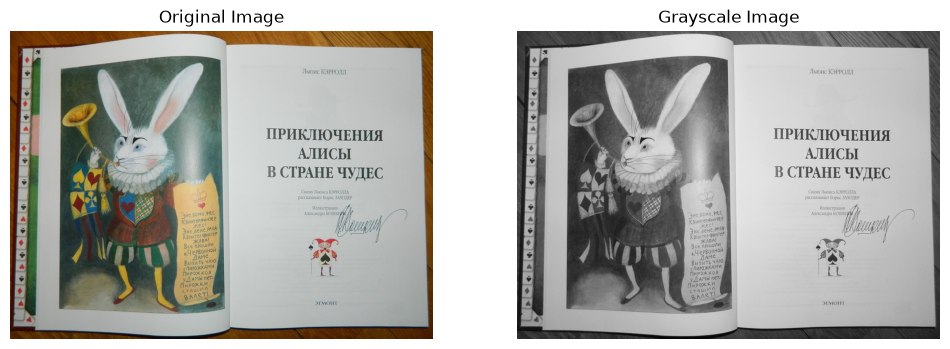

In [48]:
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

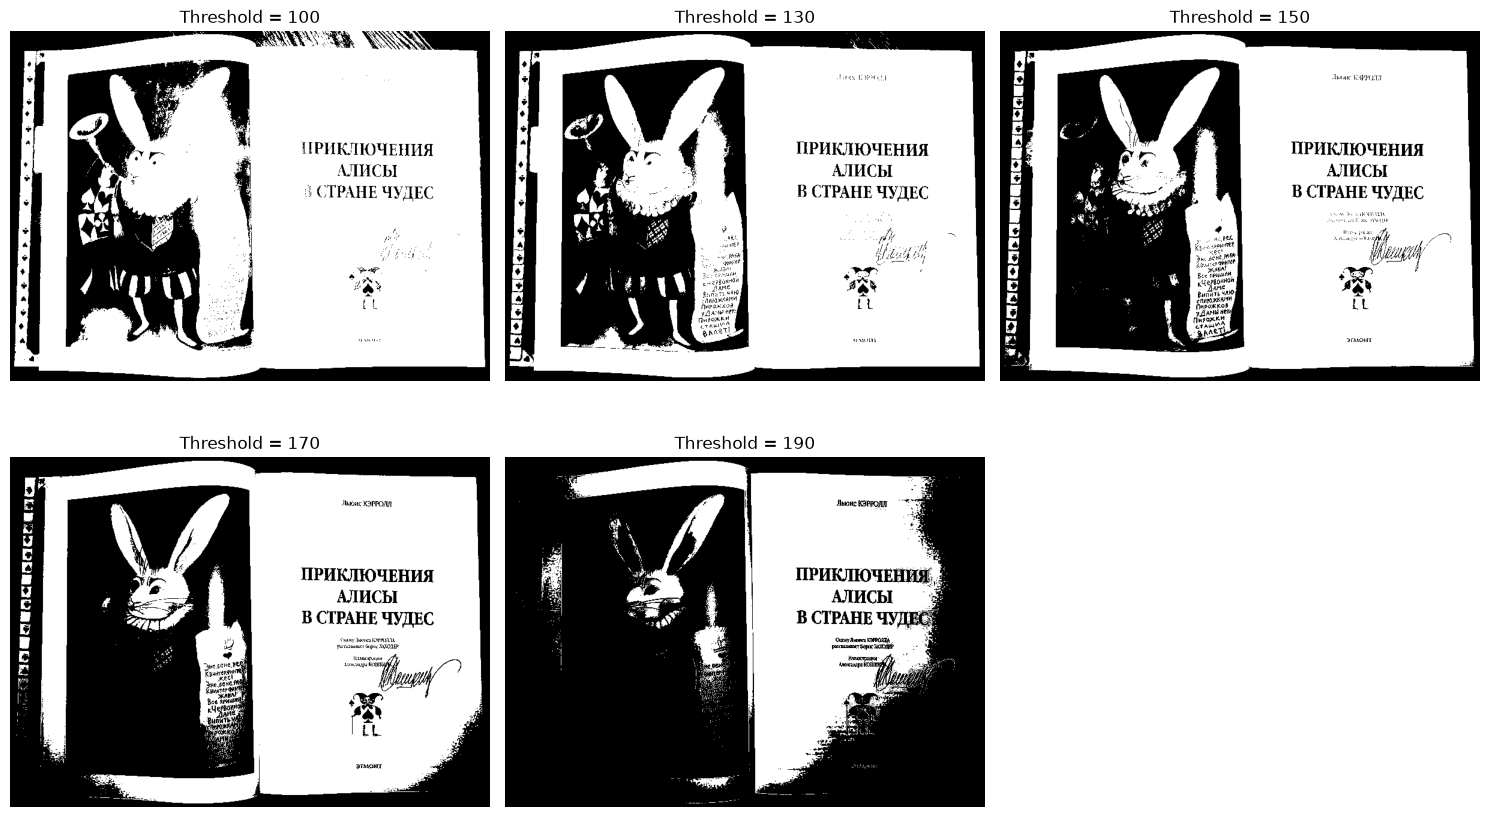

In [49]:
threshold_values = [100, 130, 150, 170, 190]

plt.figure(figsize=(15, 9))

for i, value in enumerate(threshold_values):
    _, binary_image = cv2.threshold(
        gray_image,
        value,
        255,
        cv2.THRESH_BINARY
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(binary_image, cmap="gray")
    plt.title(f"Threshold = {value}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Optimal threshold: 132.0


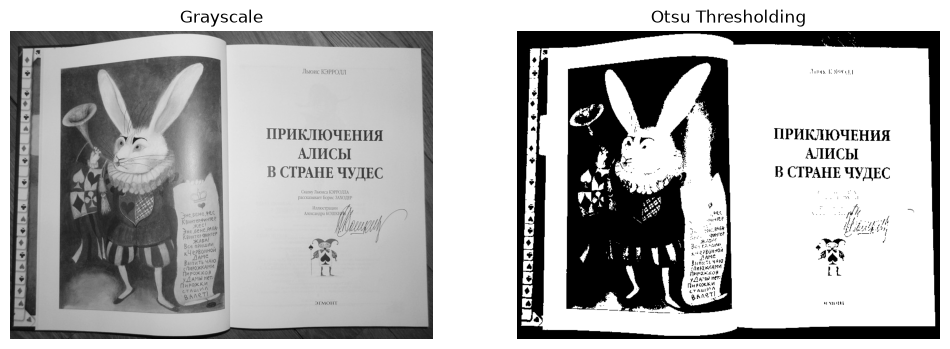

In [50]:
otsu_threshold, otsu_image = cv2.threshold(
    gray_image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Optimal threshold:", otsu_threshold)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu_image, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.show()

In [51]:
os.makedirs("processed", exist_ok=True)

output_path = "processed/document_processed.png"

success = cv2.imwrite(output_path, otsu_image)

if success:
    print("Processed image saved successfully!")
else:
    print("Error: Could not save the image!")

Processed image saved successfully!


## Task 2. Avatar Generator


In [52]:
from PIL import Image, ImageOps


In [53]:
image_path = "images/portrait.jpg"

image = Image.open(image_path)


image = ImageOps.exif_transpose(image)

image = image.convert("RGBA")

print("Image loaded successfully!")
print("Image dimensions:", image.size)

Image loaded successfully!
Image dimensions: (739, 415)


In [54]:
width, height = image.size


side = min(width, height)


left = (width - side) // 2
top = (height - side) // 2

right = left + side
bottom = top + side


square_image = image.crop((left, top, right, bottom))

print("Original dimensions:", image.size)
print("Cropped dimensions:", square_image.size)

Original dimensions: (739, 415)
Cropped dimensions: (415, 415)


In [55]:
avatar = square_image.resize(
    (250, 250),
    Image.Resampling.LANCZOS
)

print("Final avatar size:", avatar.size)

Final avatar size: (250, 250)


In [56]:
os.makedirs("avatars", exist_ok=True)

output_path = "avatars/avatar.png"

avatar.save(output_path)

print("Avatar created successfully!")
print("Saved to:", output_path)

Avatar created successfully!
Saved to: avatars/avatar.png


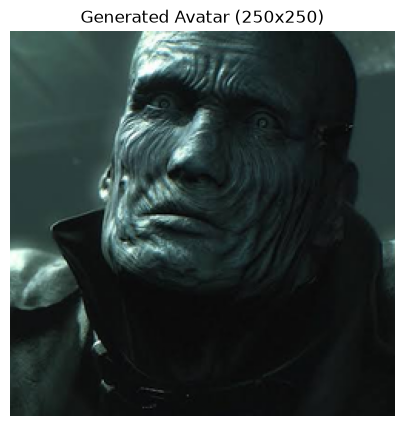

In [57]:
plt.figure(figsize=(5, 5))

plt.imshow(avatar)
plt.title("Generated Avatar (250x250)")
plt.axis("off")

plt.show()

## Task 3. Image Validation Utility



In [58]:
import cv2


In [59]:
def validate_image(image_path):

    image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)

    if image is None:
        print("Error: Image could not be loaded!")
        return

    height, width = image.shape[:2]

    if len(image.shape) == 2:
        channels = 1
    else:
        channels = image.shape[2]

    print("Image dimensions:", width, "x", height)
    print("Number of channels:", channels)

    if channels != 3:
        print("Error: Image must have exactly 3 color channels!")
        return

    if width < 800:
        print("Error: Image width must be at least 800 pixels!")
        return

    if height < 600:
        print("Error: Image height must be at least 600 pixels!")
        return

    os.makedirs("processed", exist_ok=True)

    filename = os.path.basename(image_path)
    output_path = os.path.join("processed", filename)

    success = cv2.imwrite(output_path, image)

    if success:
        print("Success! Image meets all requirements.")
        print("Saved to:", output_path)
    else:
        print("Error: Could not save the image!")

In [60]:
image_path = "images/test_image.jpg"

validate_image(image_path)

Image dimensions: 3749 x 2313
Number of channels: 3
Success! Image meets all requirements.
Saved to: processed\test_image.jpg
